In [13]:
import sys
import torch
import random
import math
import time
from collections import Counter

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import Dataset, DataLoader

import spacy

from datasets import load_dataset
from tqdm.auto import tqdm

In [2]:
import spacy

spacy_en = spacy.load("en_core_web_sm")
spacy_de = spacy.load("de_core_news_sm")

text_en = "Machine translation is very interesting."
text_de = "Maschinelle Übersetzung ist sehr interessant."

print("English:", [token.text for token in spacy_en.tokenizer(text_en)])
print("German:", [token.text for token in spacy_de.tokenizer(text_de)])

English: ['Machine', 'translation', 'is', 'very', 'interesting', '.']
German: ['Maschinelle', 'Übersetzung', 'ist', 'sehr', 'interessant', '.']


In [3]:
# dataset 

from datasets import load_dataset

dataset = load_dataset(
    "Helsinki-NLP/europarl",
    "de-en"
)

print(dataset)

/Users/tetianareshetnik/Desktop/dz_12/.venv/lib/python3.14/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
Generating train split: 100%|██████████| 1961119/1961119 [00:00<00:00, 4115828.87 examples/s]

DatasetDict({
    train: Dataset({
        features: ['translation'],
        num_rows: 1961119
    })
})


In [4]:
print(dataset["train"][0])

print("Number of examples:", len(dataset["train"]))
print("Features:", dataset["train"].features)

{'translation': {'de': 'Wiederaufnahme der Sitzungsperiode', 'en': 'Resumption of the session'}}
Number of examples: 1961119
Features: {'translation': Translation(languages=['de', 'en'])}


In [5]:
SEED = 42
NUM_SAMPLES = 50_000

subset = (
    dataset["train"]
    .shuffle(seed=SEED)
    .select(range(NUM_SAMPLES))
)

print(subset)

Dataset({
    features: ['translation'],
    num_rows: 50000
})


In [6]:
# train/validation split

split_dataset = subset.train_test_split(
    test_size=0.1,
    seed=SEED
)

train_data = split_dataset["train"]
val_data = split_dataset["test"]

print("Train size:", len(train_data))
print("Validation size:", len(val_data))

Train size: 45000
Validation size: 5000


In [7]:
example = train_data[0]

print("English:", example["translation"]["en"])
print("German:", example["translation"]["de"])

English: Passengers on package holidays will therefore benefit in the same way as those who only buy a plane ticket.
German: Deshalb werden die Pauschalreisenden davon genauso profitieren wie die Passagiere, die nur einen Flugschein kaufen.


In [8]:
def tokenize_en(text):
    return [
        token.text.lower()
        for token in spacy_en.tokenizer(text)
    ]


def tokenize_de(text):
    return [
        token.text.lower()
        for token in spacy_de.tokenizer(text)
    ]

example = train_data[0]

print("EN tokens:")
print(tokenize_en(example["translation"]["en"]))

print("\nDE tokens:")
print(tokenize_de(example["translation"]["de"]))

EN tokens:
['passengers', 'on', 'package', 'holidays', 'will', 'therefore', 'benefit', 'in', 'the', 'same', 'way', 'as', 'those', 'who', 'only', 'buy', 'a', 'plane', 'ticket', '.']

DE tokens:
['deshalb', 'werden', 'die', 'pauschalreisenden', 'davon', 'genauso', 'profitieren', 'wie', 'die', 'passagiere', ',', 'die', 'nur', 'einen', 'flugschein', 'kaufen', '.']


In [9]:
# length analysis

en_texts = [
    item["translation"]["en"]
    for item in subset
]

de_texts = [
    item["translation"]["de"]
    for item in subset
]

en_lengths = [
    len(doc)
    for doc in spacy_en.pipe(en_texts, batch_size=1000)
]

de_lengths = [
    len(doc)
    for doc in spacy_de.pipe(de_texts, batch_size=1000)
]

In [10]:
import numpy as np

print("English:")
print("Mean:", np.mean(en_lengths))
print("Median:", np.median(en_lengths))
print("95 percentile:", np.percentile(en_lengths, 95))
print("99 percentile:", np.percentile(en_lengths, 99))
print("Max:", np.max(en_lengths))

print("\nGerman:")
print("Mean:", np.mean(de_lengths))
print("Median:", np.median(de_lengths))
print("95 percentile:", np.percentile(de_lengths, 95))
print("99 percentile:", np.percentile(de_lengths, 99))
print("Max:", np.max(de_lengths))

English:
Mean: 28.07628
Median: 25.0
95 percentile: 59.0
99 percentile: 81.0
Max: 533

German:
Mean: 26.4815
Median: 24.0
95 percentile: 56.0
99 percentile: 77.0
Max: 512


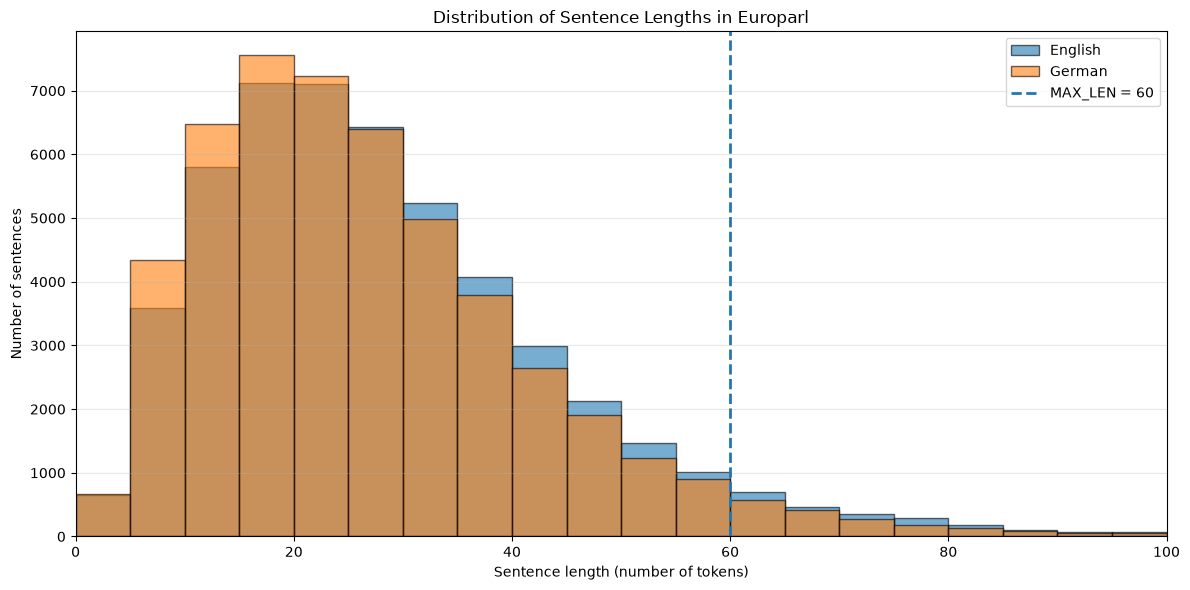

In [18]:
MAX_LEN = 60

plt.figure(figsize=(12, 6))

plt.hist(
    en_lengths,
    bins=range(0, 101, 5),
    alpha=0.6,
    label="English",
    edgecolor="black"
)

plt.hist(
    de_lengths,
    bins=range(0, 101, 5),
    alpha=0.6,
    label="German",
    edgecolor="black"
)

plt.axvline(
    MAX_LEN,
    linestyle="--",
    linewidth=2,
    label=f"MAX_LEN = {MAX_LEN}"
)

plt.xlabel("Sentence length (number of tokens)")
plt.ylabel("Number of sentences")
plt.title("Distribution of Sentence Lengths in Europarl")

plt.xlim(0, 100)
plt.legend()
plt.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()

In [19]:
# фільтрація

MAX_LEN = 60

valid_indices = [
    i
    for i, (en_len, de_len) in enumerate(zip(en_lengths, de_lengths))
    if en_len <= MAX_LEN and de_len <= MAX_LEN
]

filtered_data = subset.select(valid_indices)

print("Before filtering:", len(subset))
print("After filtering:", len(filtered_data))
print("Removed:", len(subset) - len(filtered_data))

print(
    "Remaining:",
    f"{len(filtered_data) / len(subset) * 100:.2f}%"
)

Before filtering: 50000
After filtering: 47521
Removed: 2479
Remaining: 95.04%


In [20]:
split_dataset = filtered_data.train_test_split(
    test_size=0.1,
    seed=SEED
)

train_data = split_dataset["train"]
val_data = split_dataset["test"]

print("Train size:", len(train_data))
print("Validation size:", len(val_data))


example = train_data[0]

print("English:")
print(example["translation"]["en"])

print("\nGerman:")
print(example["translation"]["de"])

filtered_en_lengths = [
    en_lengths[i]
    for i in valid_indices
]

filtered_de_lengths = [
    de_lengths[i]
    for i in valid_indices
]

print("Max English length:", max(filtered_en_lengths))
print("Max German length:", max(filtered_de_lengths))

Train size: 42768
Validation size: 4753
English:
Let us all hope that the forthcoming Commission and Council proposals will include intervention at the root of the problem, the production system itself and the need to modify it with new criteria governed by sustainable development and the need to protect consumers and public health.

German:
Hoffen wir also alle, daß die nächsten Vorschläge der Kommission und des Rates das Übel bei der Wurzel packt, bei der Produktionsweise, wo Regelungsbedarf besteht, und zwar mit neuen Kriterien, die sich von der nachhaltigen Entwicklung und dem Erfordernis des Schutzes der Verbraucher und der öffentlichen Gesundheit leiten lassen!
Max English length: 60
Max German length: 60


In [21]:
# spec tokenization
PAD_TOKEN = "<pad>"
UNK_TOKEN = "<unk>"
SOS_TOKEN = "<sos>"
EOS_TOKEN = "<eos>"

SPECIAL_TOKENS = [
    PAD_TOKEN,
    UNK_TOKEN,
    SOS_TOKEN,
    EOS_TOKEN
]

In [22]:
MIN_FREQ = 2

from collections import Counter


def build_vocab(data, language, tokenizer, min_freq=2):
    counter = Counter()

    texts = [
        example["translation"][language]
        for example in data
    ]

    for doc in tokenizer.pipe(texts, batch_size=1000):
        tokens = [token.text.lower() for token in doc]
        counter.update(tokens)

    itos = SPECIAL_TOKENS.copy()

    for token, freq in counter.items():
        if freq >= min_freq:
            itos.append(token)

    stoi = {
        token: idx
        for idx, token in enumerate(itos)
    }

    return stoi, itos, counter

In [23]:
# vocab creation

MIN_FREQ = 2

en_stoi, en_itos, en_counter = build_vocab(
    train_data,
    "en",
    spacy_en,
    MIN_FREQ
)

de_stoi, de_itos, de_counter = build_vocab(
    train_data,
    "de",
    spacy_de,
    MIN_FREQ
)

print("English vocabulary size:", len(en_itos))
print("German vocabulary size:", len(de_itos))

print("English:")
for token in SPECIAL_TOKENS:
    print(token, "->", en_stoi[token])

print("\nGerman:")
for token in SPECIAL_TOKENS:
    print(token, "->", de_stoi[token])

English vocabulary size: 13496
German vocabulary size: 22474
English:
<pad> -> 0
<unk> -> 1
<sos> -> 2
<eos> -> 3

German:
<pad> -> 0
<unk> -> 1
<sos> -> 2
<eos> -> 3


In [24]:
print("English most common:")
print(en_counter.most_common(15))

print("\nGerman most common:")
print(de_counter.most_common(15))

print("Index of 'the':", en_stoi.get("the"))
print("Index of 'die':", de_stoi.get("die"))

print(
    "Unknown word:",
    en_stoi.get("this_word_does_not_exist", en_stoi[UNK_TOKEN])
)

English most common:
[('the', 74638), (',', 49724), ('.', 41432), ('of', 34975), ('to', 33339), ('and', 27314), ('in', 23486), ('that', 17850), ('is', 17100), ('a', 16657), ('we', 11711), ('for', 11461), ('i', 11174), ('this', 11004), ('on', 10020)]

German most common:
[(',', 67664), ('.', 41819), ('die', 40392), ('der', 34564), ('und', 26846), ('in', 16180), ('zu', 12729), ('den', 11585), ('wir', 10513), ('ich', 10211), ('das', 10023), ('ist', 9811), ('für', 9736), ('von', 9371), ('es', 8044)]
Index of 'the': 9
Index of 'die': 10
Unknown word: 1


In [25]:
# Numericalization

def numericalize(text, tokenizer, stoi):
    tokens = [
        token.text.lower()
        for token in tokenizer.tokenizer(text)
    ]

    token_ids = [
        stoi.get(token, stoi[UNK_TOKEN])
        for token in tokens
    ]

    return [
        stoi[SOS_TOKEN],
        *token_ids,
        stoi[EOS_TOKEN]
    ]

In [27]:
sample = train_data[0]["translation"]

en_ids = numericalize(
    sample["en"],
    spacy_en,
    en_stoi
)

de_ids = numericalize(
    sample["de"],
    spacy_de,
    de_stoi
)

print("English:")
print(sample["en"])
print(en_ids)

print("\nGerman:")
print(sample["de"])
print(de_ids)

print([en_itos[idx] for idx in en_ids])

English:
Let us all hope that the forthcoming Commission and Council proposals will include intervention at the root of the problem, the production system itself and the need to modify it with new criteria governed by sustainable development and the need to protect consumers and public health.
[2, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 9, 19, 20, 9, 21, 22, 9, 23, 24, 25, 12, 9, 26, 27, 28, 29, 30, 31, 32, 33, 34, 35, 36, 12, 9, 26, 27, 37, 38, 12, 39, 40, 41, 3]

German:
Hoffen wir also alle, daß die nächsten Vorschläge der Kommission und des Rates das Übel bei der Wurzel packt, bei der Produktionsweise, wo Regelungsbedarf besteht, und zwar mit neuen Kriterien, die sich von der nachhaltigen Entwicklung und dem Erfordernis des Schutzes der Verbraucher und der öffentlichen Gesundheit leiten lassen!
[2, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20, 13, 21, 1, 8, 20, 13, 22, 8, 23, 1, 24, 8, 15, 25, 26, 27, 28, 8, 10, 29, 30, 13, 31, 32, 15, 33, 34, 16, 35, 

In [29]:
# translationDataset

from torch.utils.data import Dataset


class TranslationDataset(Dataset):
    def __init__(
        self,
        data,
        src_tokenizer,
        trg_tokenizer,
        src_stoi,
        trg_stoi
    ):
        self.data = data
        self.src_tokenizer = src_tokenizer
        self.trg_tokenizer = trg_tokenizer
        self.src_stoi = src_stoi
        self.trg_stoi = trg_stoi

    def __len__(self):
        return len(self.data)

    def __getitem__(self, idx):
        translation = self.data[idx]["translation"]

        src_ids = numericalize(
            translation["en"],
            self.src_tokenizer,
            self.src_stoi
        )

        trg_ids = numericalize(
            translation["de"],
            self.trg_tokenizer,
            self.trg_stoi
        )

        return (
            torch.tensor(src_ids, dtype=torch.long),
            torch.tensor(trg_ids, dtype=torch.long)
        )

In [30]:
train_dataset = TranslationDataset(
    train_data,
    spacy_en,
    spacy_de,
    en_stoi,
    de_stoi
)

val_dataset = TranslationDataset(
    val_data,
    spacy_en,
    spacy_de,
    en_stoi,
    de_stoi
)

print("Train dataset:", len(train_dataset))
print("Validation dataset:", len(val_dataset))

Train dataset: 42768
Validation dataset: 4753


In [31]:
from torch.nn.utils.rnn import pad_sequence


SRC_PAD_IDX = en_stoi[PAD_TOKEN]
TRG_PAD_IDX = de_stoi[PAD_TOKEN]


def collate_fn(batch):
    src_batch, trg_batch = zip(*batch)

    src_batch = pad_sequence(
        src_batch,
        padding_value=SRC_PAD_IDX
    )

    trg_batch = pad_sequence(
        trg_batch,
        padding_value=TRG_PAD_IDX
    )

    return src_batch, trg_batch

In [32]:
from torch.utils.data import DataLoader

BATCH_SIZE = 64

train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    collate_fn=collate_fn
)

val_loader = DataLoader(
    val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    collate_fn=collate_fn
)

In [33]:
src_batch, trg_batch = next(iter(train_loader))

print("Source batch shape:", src_batch.shape)
print("Target batch shape:", trg_batch.shape)

print("\nSource dtype:", src_batch.dtype)
print("Target dtype:", trg_batch.dtype)

print("\nSource device:", src_batch.device)

Source batch shape: torch.Size([57, 64])
Target batch shape: torch.Size([60, 64])

Source dtype: torch.int64
Target dtype: torch.int64

Source device: cpu


In [34]:
# Encoder — Bidirectional GRU

class Encoder(nn.Module):
    def __init__(
        self,
        input_dim,
        emb_dim,
        enc_hid_dim,
        dec_hid_dim,
        dropout
    ):
        super().__init__()

        self.embedding = nn.Embedding(
            input_dim,
            emb_dim,
            padding_idx=SRC_PAD_IDX
        )

        self.rnn = nn.GRU(
            emb_dim,
            enc_hid_dim,
            bidirectional=True
        )

        self.fc = nn.Linear(
            enc_hid_dim * 2,
            dec_hid_dim
        )

        self.dropout = nn.Dropout(dropout)

    def forward(self, src):

        # src: [src_len, batch_size]

        embedded = self.dropout(
            self.embedding(src)
        )

        # embedded:
        # [src_len, batch_size, emb_dim]

        outputs, hidden = self.rnn(embedded)

        # outputs:
        # [src_len, batch_size, enc_hid_dim * 2]
        #
        # hidden:
        # [2, batch_size, enc_hid_dim]

        hidden = torch.tanh(
            self.fc(
                torch.cat(
                    (hidden[-2], hidden[-1]),
                    dim=1
                )
            )
        )

        # hidden:
        # [batch_size, dec_hid_dim]

        return outputs, hidden

In [35]:
class Attention(nn.Module):
    def __init__(
        self,
        enc_hid_dim,
        dec_hid_dim
    ):
        super().__init__()

        self.attn = nn.Linear(
            enc_hid_dim * 2 + dec_hid_dim,
            dec_hid_dim
        )

        self.v = nn.Linear(
            dec_hid_dim,
            1,
            bias=False
        )

    def forward(
        self,
        hidden,
        encoder_outputs,
        mask
    ):

        # hidden:
        # [batch_size, dec_hid_dim]

        # encoder_outputs:
        # [src_len, batch_size, enc_hid_dim * 2]

        batch_size = encoder_outputs.shape[1]
        src_len = encoder_outputs.shape[0]

        hidden = hidden.unsqueeze(1).repeat(
            1,
            src_len,
            1
        )

        encoder_outputs = encoder_outputs.permute(
            1,
            0,
            2
        )

        # hidden:
        # [batch_size, src_len, dec_hid_dim]

        # encoder_outputs:
        # [batch_size, src_len, enc_hid_dim * 2]

        energy = torch.tanh(
            self.attn(
                torch.cat(
                    (hidden, encoder_outputs),
                    dim=2
                )
            )
        )

        # energy:
        # [batch_size, src_len, dec_hid_dim]

        attention = self.v(energy).squeeze(2)

        # attention:
        # [batch_size, src_len]

        attention = attention.masked_fill(
            mask == 0,
            -1e10
        )

        return torch.softmax(
            attention,
            dim=1
        )

In [36]:
class Decoder(nn.Module):
    def __init__(
        self,
        output_dim,
        emb_dim,
        enc_hid_dim,
        dec_hid_dim,
        dropout,
        attention
    ):
        super().__init__()

        self.output_dim = output_dim
        self.attention = attention

        self.embedding = nn.Embedding(
            output_dim,
            emb_dim,
            padding_idx=TRG_PAD_IDX
        )

        self.rnn = nn.GRU(
            enc_hid_dim * 2 + emb_dim,
            dec_hid_dim
        )

        self.fc_out = nn.Linear(
            enc_hid_dim * 2
            + dec_hid_dim
            + emb_dim,
            output_dim
        )

        self.dropout = nn.Dropout(dropout)

    def forward(
        self,
        input,
        hidden,
        encoder_outputs,
        mask
    ):

        # input:
        # [batch_size]

        input = input.unsqueeze(0)

        # [1, batch_size]

        embedded = self.dropout(
            self.embedding(input)
        )

        # [1, batch_size, emb_dim]

        a = self.attention(
            hidden,
            encoder_outputs,
            mask
        )

        # [batch_size, src_len]

        a = a.unsqueeze(1)

        encoder_outputs = encoder_outputs.permute(
            1,
            0,
            2
        )

        weighted = torch.bmm(
            a,
            encoder_outputs
        )

        # weighted:
        # [batch_size, 1, enc_hid_dim * 2]

        weighted = weighted.permute(
            1,
            0,
            2
        )

        rnn_input = torch.cat(
            (embedded, weighted),
            dim=2
        )

        output, hidden_new = self.rnn(
            rnn_input,
            hidden.unsqueeze(0)
        )

        embedded = embedded.squeeze(0)
        output = output.squeeze(0)
        weighted = weighted.squeeze(0)

        prediction = self.fc_out(
            torch.cat(
                (output, weighted, embedded),
                dim=1
            )
        )

        # prediction:
        # [batch_size, output_dim]

        return (
            prediction,
            hidden_new.squeeze(0),
            a.squeeze(1)
        )

In [37]:
class Seq2Seq(nn.Module):
    def __init__(
        self,
        encoder,
        decoder,
        src_pad_idx,
        device
    ):
        super().__init__()

        self.encoder = encoder
        self.decoder = decoder
        self.src_pad_idx = src_pad_idx
        self.device = device

    def create_mask(self, src):
        return (
            src != self.src_pad_idx
        ).permute(1, 0)

    def forward(
        self,
        src,
        trg,
        teacher_forcing_ratio=0.5
    ):

        batch_size = src.shape[1]
        trg_len = trg.shape[0]
        trg_vocab_size = self.decoder.output_dim

        outputs = torch.zeros(
            trg_len,
            batch_size,
            trg_vocab_size,
            device=self.device
        )

        encoder_outputs, hidden = self.encoder(src)

        input = trg[0]

        mask = self.create_mask(src)

        for t in range(1, trg_len):

            output, hidden, _ = self.decoder(
                input,
                hidden,
                encoder_outputs,
                mask
            )

            outputs[t] = output

            teacher_force = (
                random.random()
                < teacher_forcing_ratio
            )

            top1 = output.argmax(1)

            input = (
                trg[t]
                if teacher_force
                else top1
            )

        return outputs

In [38]:
# model creation

INPUT_DIM = len(en_itos)
OUTPUT_DIM = len(de_itos)

ENC_EMB_DIM = 256
DEC_EMB_DIM = 256

ENC_HID_DIM = 256
DEC_HID_DIM = 256

ENC_DROPOUT = 0.5
DEC_DROPOUT = 0.5

attention = Attention(
    ENC_HID_DIM,
    DEC_HID_DIM
)

encoder = Encoder(
    INPUT_DIM,
    ENC_EMB_DIM,
    ENC_HID_DIM,
    DEC_HID_DIM,
    ENC_DROPOUT
)

decoder = Decoder(
    OUTPUT_DIM,
    DEC_EMB_DIM,
    ENC_HID_DIM,
    DEC_HID_DIM,
    DEC_DROPOUT,
    attention
)

model = Seq2Seq(
    encoder,
    decoder,
    SRC_PAD_IDX,
    device
).to(device)

In [39]:
print(model)

print(
    f"\nTrainable parameters: "
    f"{sum(p.numel() for p in model.parameters() if p.requires_grad):,}"
)

Seq2Seq(
  (encoder): Encoder(
    (embedding): Embedding(13496, 256, padding_idx=0)
    (rnn): GRU(256, 256, bidirectional=True)
    (fc): Linear(in_features=512, out_features=256, bias=True)
    (dropout): Dropout(p=0.5, inplace=False)
  )
  (decoder): Decoder(
    (attention): Attention(
      (attn): Linear(in_features=768, out_features=256, bias=True)
      (v): Linear(in_features=256, out_features=1, bias=False)
    )
    (embedding): Embedding(22474, 256, padding_idx=0)
    (rnn): GRU(768, 256)
    (fc_out): Linear(in_features=1024, out_features=22474, bias=True)
    (dropout): Dropout(p=0.5, inplace=False)
  )
)

Trainable parameters: 34,150,090


In [40]:
src_batch, trg_batch = next(iter(train_loader))

src_batch = src_batch.to(device)
trg_batch = trg_batch.to(device)

with torch.no_grad():
    output = model(
        src_batch,
        trg_batch,
        teacher_forcing_ratio=0.5
    )

print("Model output shape:", output.shape)
print("Target shape:", trg_batch.shape)

Model output shape: torch.Size([49, 64, 22474])
Target shape: torch.Size([49, 64])


In [41]:
# loos and optimizer

optimizer = optim.Adam(
    model.parameters(),
    lr=0.001
)

criterion = nn.CrossEntropyLoss(
    ignore_index=TRG_PAD_IDX
)

In [66]:
def train_epoch(
    model,
    iterator,
    optimizer,
    criterion,
    teacher_forcing_ratio,
    clip=1.0
):
    model.train()

    epoch_loss = 0

    progress_bar = tqdm(
        iterator,
        desc="Training",
        leave=False
    )

    for src, trg in progress_bar:

        src = src.to(device)
        trg = trg.to(device)

        optimizer.zero_grad()

        output = model(
            src,
            trg,
            teacher_forcing_ratio=teacher_forcing_ratio
        )

        output_dim = output.shape[-1]

        output = output[1:].reshape(
            -1,
            output_dim
        )

        trg = trg[1:].reshape(-1)

        loss = criterion(
            output,
            trg
        )

        loss.backward()

        torch.nn.utils.clip_grad_norm_(
            model.parameters(),
            clip
        )

        optimizer.step()

        epoch_loss += loss.item()

        progress_bar.set_postfix(
            loss=f"{loss.item():.3f}"
        )

    return epoch_loss / len(iterator)

In [67]:
FINE_TUNE_EPOCHS = 5
CLIP = 1.0

teacher_forcing_schedule = [
    0.50,
    0.45,
    0.40,
    0.35,
    0.30
]

fine_train_losses = []
fine_val_losses = []

best_fine_val_loss = best_val_loss

print("Fine-tuning epochs:", FINE_TUNE_EPOCHS)
print("Teacher forcing:", teacher_forcing_schedule)
print("Best validation loss:", best_fine_val_loss)

Fine-tuning epochs: 5
Teacher forcing: [0.5, 0.45, 0.4, 0.35, 0.3]
Best validation loss: 5.394674339294434


In [68]:
# fine-tuning loop

for epoch in range(FINE_TUNE_EPOCHS):

    start_time = time.time()

    teacher_forcing_ratio = teacher_forcing_schedule[epoch]

    train_loss = train_epoch(
        model,
        train_loader,
        optimizer,
        criterion,
        teacher_forcing_ratio,
        CLIP
    )

    val_loss = evaluate(
        model,
        val_loader,
        criterion
    )

    scheduler.step(val_loss)

    fine_train_losses.append(train_loss)
    fine_val_losses.append(val_loss)

    if val_loss < best_fine_val_loss:
        best_fine_val_loss = val_loss

        torch.save(
            model.state_dict(),
            "best_finetuned_translation_model.pt"
        )

    current_lr = optimizer.param_groups[0]["lr"]

    end_time = time.time()

    print(
        f"Fine-tune Epoch: {epoch + 1:02}/{FINE_TUNE_EPOCHS} | "
        f"Time: {(end_time - start_time) / 60:.1f} min"
    )

    print(
        f"\tTeacher Forcing: {teacher_forcing_ratio:.2f}"
    )

    print(
        f"\tLearning Rate: {current_lr:.6f}"
    )

    print(
        f"\tTrain Loss: {train_loss:.3f} | "
        f"Train PPL: {math.exp(train_loss):.3f}"
    )

    print(
        f"\tVal Loss: {val_loss:.3f} | "
        f"Val PPL: {math.exp(val_loss):.3f}"
    )

Fine-tune Epoch: 01/5 | Time: 3.3 min
	Teacher Forcing: 0.50
	Learning Rate: 0.000500
	Train Loss: 4.393 | Train PPL: 80.863
	Val Loss: 5.308 | Val PPL: 201.878


Fine-tune Epoch: 02/5 | Time: 3.3 min
	Teacher Forcing: 0.45
	Learning Rate: 0.000500
	Train Loss: 4.242 | Train PPL: 69.536
	Val Loss: 5.280 | Val PPL: 196.429


Fine-tune Epoch: 03/5 | Time: 3.3 min
	Teacher Forcing: 0.40
	Learning Rate: 0.000500
	Train Loss: 4.161 | Train PPL: 64.118
	Val Loss: 5.230 | Val PPL: 186.851


Fine-tune Epoch: 04/5 | Time: 3.3 min
	Teacher Forcing: 0.35
	Learning Rate: 0.000500
	Train Loss: 4.109 | Train PPL: 60.862
	Val Loss: 5.201 | Val PPL: 181.504


Fine-tune Epoch: 05/5 | Time: 3.3 min
	Teacher Forcing: 0.30
	Learning Rate: 0.000500
	Train Loss: 4.071 | Train PPL: 58.643
	Val Loss: 5.195 | Val PPL: 180.409


In [69]:
model.load_state_dict(
    torch.load(
        "best_finetuned_translation_model.pt",
        map_location=device
    )
)

model = model.to(device)
model.eval()

print("Best fine-tuned model loaded")
print("Best fine-tuned validation loss:", best_fine_val_loss)

Best fine-tuned model loaded
Best fine-tuned validation loss: 5.195224386850993


In [70]:
for i in range(5):

    example = val_data[i]["translation"]

    src_sentence = example["en"]
    reference = example["de"]

    translation, src_tokens, attention = translate_sentence(
        src_sentence,
        model,
        spacy_en,
        en_stoi,
        en_itos,
        de_stoi,
        de_itos,
        device
    )

    print("=" * 80)

    print("SOURCE:")
    print(src_sentence)

    print("\nREFERENCE:")
    print(reference)

    print("\nPREDICTION:")
    print(" ".join(translation))

    print()

SOURCE:
I mention the areas that are worst affected by the enlargement and that, in theory, became wealthy overnight due to the well-documented statistical effect.

REFERENCE:
Ich erwähne die Gebiete, die am gravierendsten von der Erweiterung betroffen sind und die theoretisch infolge eines nachgewiesenen statistischen Effekts über Nacht wohlhabend wurden.

PREDICTION:
ich finde die bereiche , dass die schlimmsten der erweiterung erweiterung erweiterung und und , , , , , , , die die .

SOURCE:
Finally, with regard to the Intergovernmental Conference for revising the Treaties, my suggestion is that you ignore the current draft.

REFERENCE:
Abschließend schlage ich bezüglich der Regierungskonferenz zur Revision der Verträge vor, den derzeitigen Entwurf zu ignorieren.

PREDICTION:
schließlich , die regierungskonferenz regierungskonferenz regierungskonferenz regierungskonferenz , die ich , , , , , dass sie die gegenwärtige .

SOURCE:
That can and will happen.

REFERENCE:
Das wird und kann 

In [43]:
# validation

def evaluate(
    model,
    iterator,
    criterion
):
    model.eval()

    epoch_loss = 0

    with torch.no_grad():

        for src, trg in iterator:

            src = src.to(device)
            trg = trg.to(device)

            output = model(
                src,
                trg,
                teacher_forcing_ratio=0.0
            )

            output_dim = output.shape[-1]

            output = output[1:].reshape(
                -1,
                output_dim
            )

            trg = trg[1:].reshape(-1)

            loss = criterion(
                output,
                trg
            )

            epoch_loss += loss.item()

    return epoch_loss / len(iterator)

In [44]:
# learning

N_EPOCHS = 5
CLIP = 1.0

train_losses = []
val_losses = []

best_val_loss = float("inf")

for epoch in range(N_EPOCHS):

    start_time = time.time()

    train_loss = train_epoch(
        model,
        train_loader,
        optimizer,
        criterion,
        CLIP
    )

    val_loss = evaluate(
        model,
        val_loader,
        criterion
    )

    end_time = time.time()

    train_losses.append(train_loss)
    val_losses.append(val_loss)

    if val_loss < best_val_loss:
        best_val_loss = val_loss

        torch.save(
            model.state_dict(),
            "best_translation_model.pt"
        )

    print(
        f"Epoch: {epoch + 1:02}/{N_EPOCHS} | "
        f"Time: {(end_time - start_time) / 60:.1f} min"
    )

    print(
        f"\tTrain Loss: {train_loss:.3f} | "
        f"Train PPL: {math.exp(train_loss):.3f}"
    )

    print(
        f"\tVal Loss:   {val_loss:.3f} | "
        f"Val PPL:   {math.exp(val_loss):.3f}"
    )

Epoch: 01/5 | Time: 3.3 min
	Train Loss: 5.913 | Train PPL: 369.971
	Val Loss:   5.685 | Val PPL:   294.538


Epoch: 02/5 | Time: 3.3 min
	Train Loss: 5.093 | Train PPL: 162.855
	Val Loss:   5.410 | Val PPL:   223.555


Epoch: 03/5 | Time: 3.3 min
	Train Loss: 4.663 | Train PPL: 106.003
	Val Loss:   5.395 | Val PPL:   220.230


Epoch: 04/5 | Time: 3.2 min
	Train Loss: 4.357 | Train PPL: 78.007
	Val Loss:   5.465 | Val PPL:   236.185


Epoch: 05/5 | Time: 3.2 min
	Train Loss: 4.127 | Train PPL: 61.989
	Val Loss:   5.406 | Val PPL:   222.818


In [62]:
model.load_state_dict(
    torch.load(
        "best_translation_model.pt",
        map_location=device
    )
)

model.eval()

print("Best model loaded.")

Best model loaded.


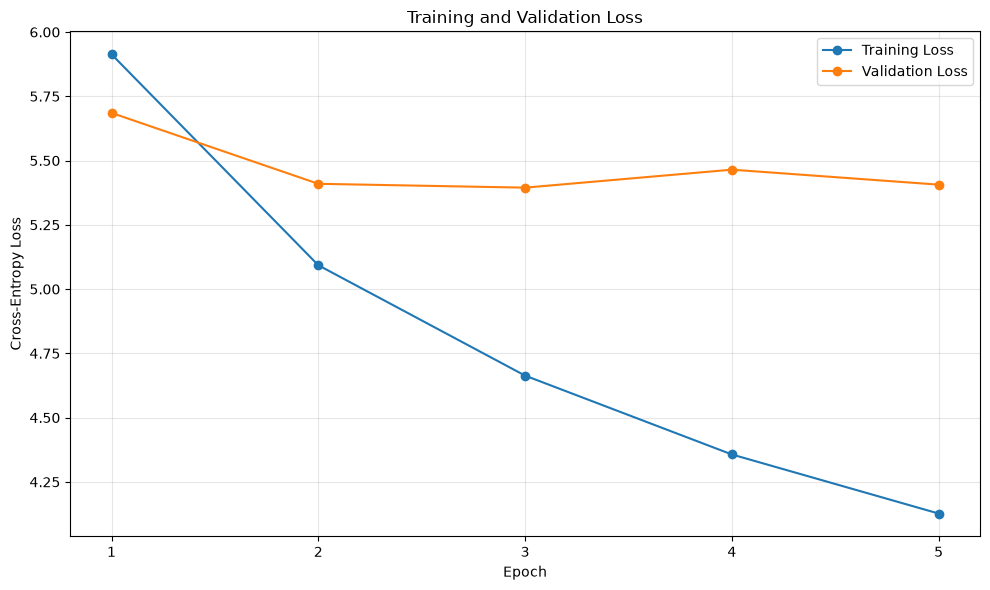

In [46]:
epochs = range(1, len(train_losses) + 1)

plt.figure(figsize=(10, 6))

plt.plot(
    epochs,
    train_losses,
    marker="o",
    label="Training Loss"
)

plt.plot(
    epochs,
    val_losses,
    marker="o",
    label="Validation Loss"
)

plt.xlabel("Epoch")
plt.ylabel("Cross-Entropy Loss")
plt.title("Training and Validation Loss")

plt.xticks(epochs)
plt.grid(alpha=0.3)
plt.legend()

plt.tight_layout()
plt.show()

Протягом навчання значення training loss стабільно зменшувалося з 5.913 до 4.127, що свідчить про навчання моделі на тренувальних даних. Validation loss зменшився з 5.685 до мінімального значення 5.395 на третій епосі, після чого перестав стабільно покращуватися. Така поведінка може свідчити про початок перенавчання. Тому для подальшого аналізу використовується модель з найменшим validation loss.

In [53]:
def translate_sentence(
    sentence,
    model,
    src_tokenizer,
    src_stoi,
    src_itos,
    trg_stoi,
    trg_itos,
    device,
    max_len=60
):
    model.eval()

    tokens = [
        token.text.lower()
        for token in src_tokenizer.tokenizer(sentence)
    ]

    tokens = [
        SOS_TOKEN,
        *tokens,
        EOS_TOKEN
    ]

    src_indexes = [
        src_stoi.get(token, src_stoi[UNK_TOKEN])
        for token in tokens
    ]

    src_tensor = torch.LongTensor(
        src_indexes
    ).unsqueeze(1).to(device)

    with torch.no_grad():
        encoder_outputs, hidden = model.encoder(
            src_tensor
        )

    mask = model.create_mask(src_tensor)

    trg_index = trg_stoi[SOS_TOKEN]

    trg_tokens = []
    attentions = []

    for _ in range(max_len):

        trg_tensor = torch.LongTensor(
            [trg_index]
        ).to(device)

        with torch.no_grad():

            output, hidden, attention = model.decoder(
                trg_tensor,
                hidden,
                encoder_outputs,
                mask
            )

        pred_token = output.argmax(1).item()

        if pred_token == trg_stoi[EOS_TOKEN]:
                break

        trg_tokens.append(
            trg_itos[pred_token]
        )

        attentions.append(
            attention.squeeze(0).cpu().numpy()
        )

        trg_index = pred_token

    return trg_tokens, tokens, np.array(attentions)

In [54]:
for i in range(5):

    example = val_data[i]["translation"]

    src_sentence = example["en"]
    reference = example["de"]

    translation, src_tokens, attention = translate_sentence(
        src_sentence,
        model,
        spacy_en,
        en_stoi,
        en_itos,
        de_stoi,
        de_itos,
        device
    )

    print("=" * 80)

    print("SOURCE:")
    print(src_sentence)

    print("\nREFERENCE:")
    print(reference)

    print("\nPREDICTION:")
    print(" ".join(translation))

    print()

SOURCE:
I mention the areas that are worst affected by the enlargement and that, in theory, became wealthy overnight due to the well-documented statistical effect.

REFERENCE:
Ich erwähne die Gebiete, die am gravierendsten von der Erweiterung betroffen sind und die theoretisch infolge eines nachgewiesenen statistischen Effekts über Nacht wohlhabend wurden.

PREDICTION:
ich erwähnen die bereiche , dass die die erweiterung der erweiterung erweiterung erweiterung und , , , die , die , die die <unk> .

SOURCE:
Finally, with regard to the Intergovernmental Conference for revising the Treaties, my suggestion is that you ignore the current draft.

REFERENCE:
Abschließend schlage ich bezüglich der Regierungskonferenz zur Revision der Verträge vor, den derzeitigen Entwurf zu ignorieren.

PREDICTION:
schließlich möchte ich die regierungskonferenz regierungskonferenz , regierungskonferenz , , , , , , dass sie die gegenwärtige der entwurf .

SOURCE:
That can and will happen.

REFERENCE:
Das wird u

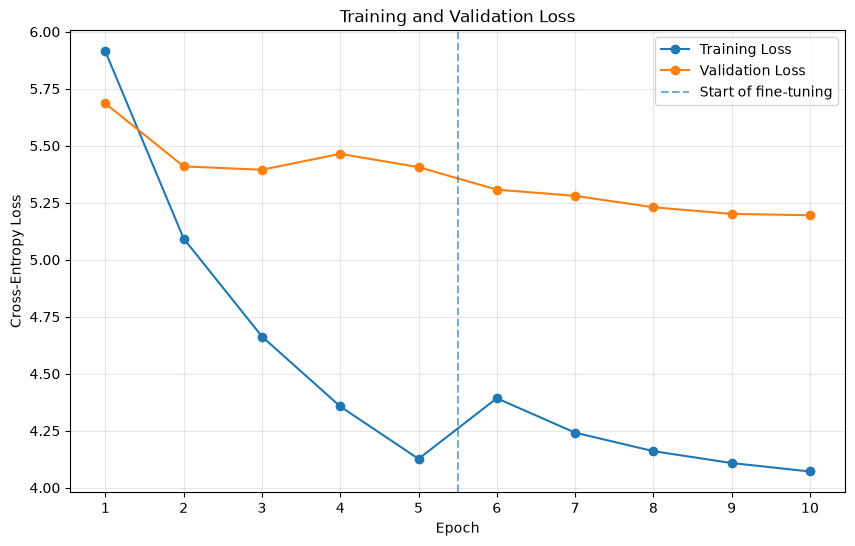

In [73]:
all_train_losses = train_losses + fine_train_losses
all_val_losses = val_losses + fine_val_losses

epochs = range(1, len(all_train_losses) + 1)

plt.figure(figsize=(10, 6))

plt.plot(
    epochs,
    all_train_losses,
    marker="o",
    label="Training Loss"
)

plt.plot(
    epochs,
    all_val_losses,
    marker="o",
    label="Validation Loss"
)

plt.axvline(
    x=5.5,
    linestyle="--",
    alpha=0.6,
    label="Start of fine-tuning"
)

plt.xlabel("Epoch")
plt.ylabel("Cross-Entropy Loss")
plt.title("Training and Validation Loss")

plt.xticks(epochs)
plt.grid(alpha=0.3)
plt.legend()


Протягом початкових п'яти епох значення training loss зменшилося з 5.913 до 4.127, що свідчить про поступове навчання Seq2Seq-моделі. Validation loss зменшився з 5.685 до мінімального значення близько 5.395, однак після третьої епохи його покращення практично припинилося, що вказує на початок перенавчання.
Для покращення моделі було виконано додатковий етап fine-tuning із меншим learning rate та поступовим зменшенням teacher forcing. У результаті validation loss знизився приблизно з 5.395 до 5.195. Водночас між training та validation loss залишається помітний розрив, тому модель має ознаки перенавчання та обмежену здатність до узагальнення на нових реченнях.
Аналіз прикладів перекладу показав, що модель навчилася правильно перекладати окремі слова та короткі фрази, однак у складніших реченнях спостерігаються повторення слів і граматичні помилки. Це є одним з обмежень побудованої базової Seq2Seq GRU-моделі.

In [55]:
def plot_attention(
    sentence,
    translation,
    attention,
    title="Attention"
):
    plt.figure(
        figsize=(
            max(10, len(sentence) * 0.5),
            max(6, len(translation) * 0.4)
        )
    )

    sns.heatmap(
        attention,
        xticklabels=sentence,
        yticklabels=translation,
        cmap="viridis",
        cbar=True
    )

    plt.xlabel("Source sentence (English)")
    plt.ylabel("Generated translation (German)")
    plt.title(title)

    plt.xticks(
        rotation=45,
        ha="right"
    )

    plt.yticks(rotation=0)

    plt.tight_layout()
    plt.show()

In [56]:
example = val_data[2]["translation"]

translation, src_tokens, attention = translate_sentence(
    example["en"],
    model,
    spacy_en,
    en_stoi,
    en_itos,
    de_stoi,
    de_itos,
    device
)

print("Source:")
print(example["en"])

print("\nReference:")
print(example["de"])

print("\nPrediction:")
print(" ".join(translation))

print("\nAttention shape:")
print(attention.shape)

Source:
That can and will happen.

Reference:
Das wird und kann passieren.

Prediction:
das kann und und und .

Attention shape:
(6, 8)


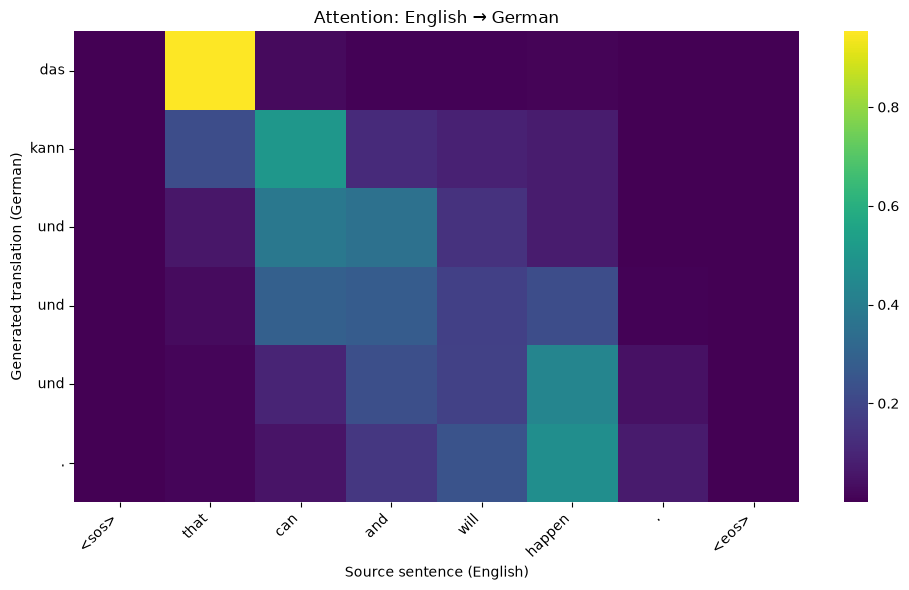

In [57]:
plot_attention(
    src_tokens,
    translation,
    attention,
    title="Attention: English → German"
)

Аналіз механізму Attention. На тепловій карті видно, що модель навчилася пов'язувати окремі слова вихідного та цільового речень. Наприклад, під час генерації слова das найбільша вага attention припадає на англійське that, а під час генерації kann увага зміщується до can. Надалі attention поступово переміщується вздовж вихідного речення до слів and, will та happen. Це свідчить про те, що механізм attention навчився певному вирівнюванню між мовами. Водночас переклад містить повторення слова und, хоча фокус attention продовжує змінюватися. Отже, основним обмеженням поточної моделі є не відсутність роботи attention, а недостатньо якісно навчений Decoder.

In [63]:
model.load_state_dict(
    torch.load(
        "best_translation_model.pt",
        map_location=device
    )
)

model = model.to(device)

print("Best model loaded")

Best model loaded


In [64]:
optimizer = optim.Adam(
    model.parameters(),
    lr=0.0005
)

print(
    "Learning rate:",
    optimizer.param_groups[0]["lr"]
)

Learning rate: 0.0005


In [65]:
scheduler = optim.lr_scheduler.ReduceLROnPlateau(
    optimizer,
    mode="min",
    factor=0.5,
    patience=1
)

print("Scheduler created")

Scheduler created


Attention Heatmap — Short Sentence

SOURCE:
That can and will happen.

REFERENCE:
Das wird und kann passieren.

PREDICTION:
dies können und und . .

Attention shape: (6, 8)


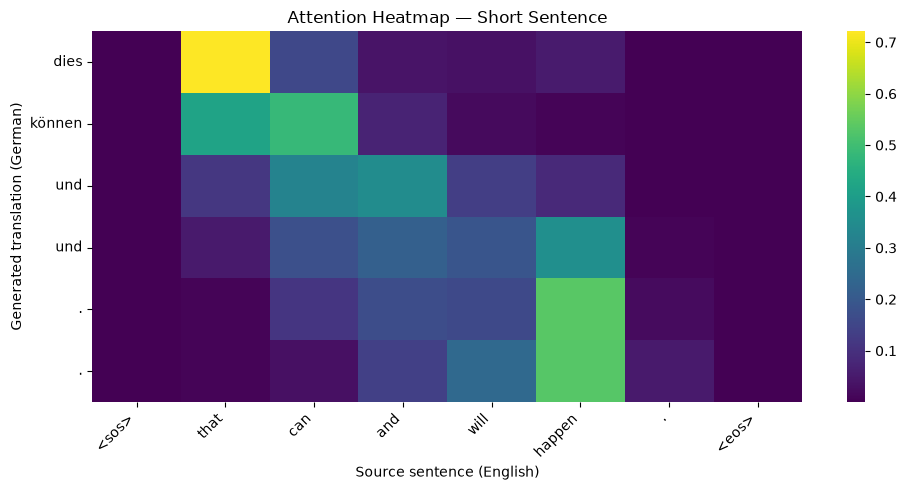

Attention Heatmap — Medium Sentence

SOURCE:
Mr President, I am very glad that you are being very tolerant on time this morning.

REFERENCE:
Herr Präsident, ich freue mich sehr über Ihre Nachsicht, was die Einhaltung der Redezeit heute Morgen betrifft.

PREDICTION:
herr präsident , ich freue sehr froh , dass sie sehr sehr morgen früh .

Attention shape: (15, 20)


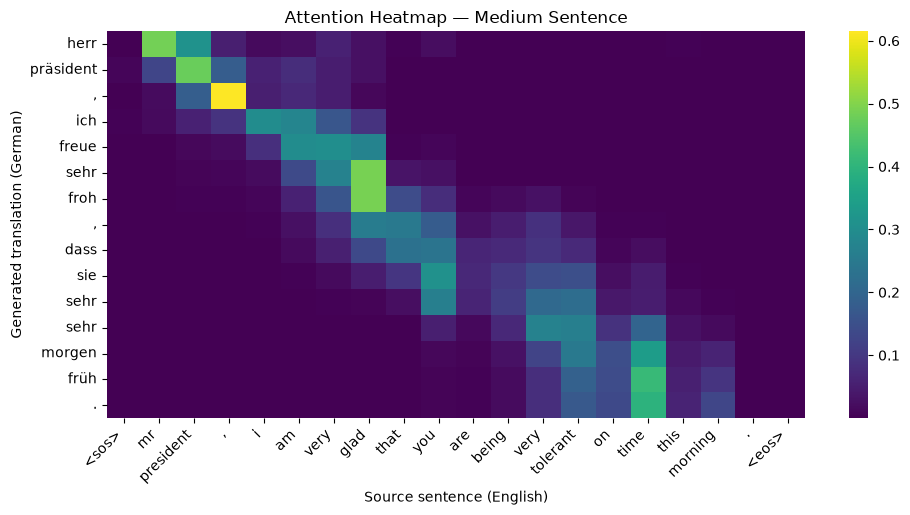

Attention Heatmap — Long Sentence

SOURCE:
I mention the areas that are worst affected by the enlargement and that, in theory, became wealthy overnight due to the well-documented statistical effect.

REFERENCE:
Ich erwähne die Gebiete, die am gravierendsten von der Erweiterung betroffen sind und die theoretisch infolge eines nachgewiesenen statistischen Effekts über Nacht wohlhabend wurden.

PREDICTION:
ich finde die bereiche , dass die schlimmsten der erweiterung erweiterung erweiterung und und , , , , , , , die die .

Attention shape: (24, 31)


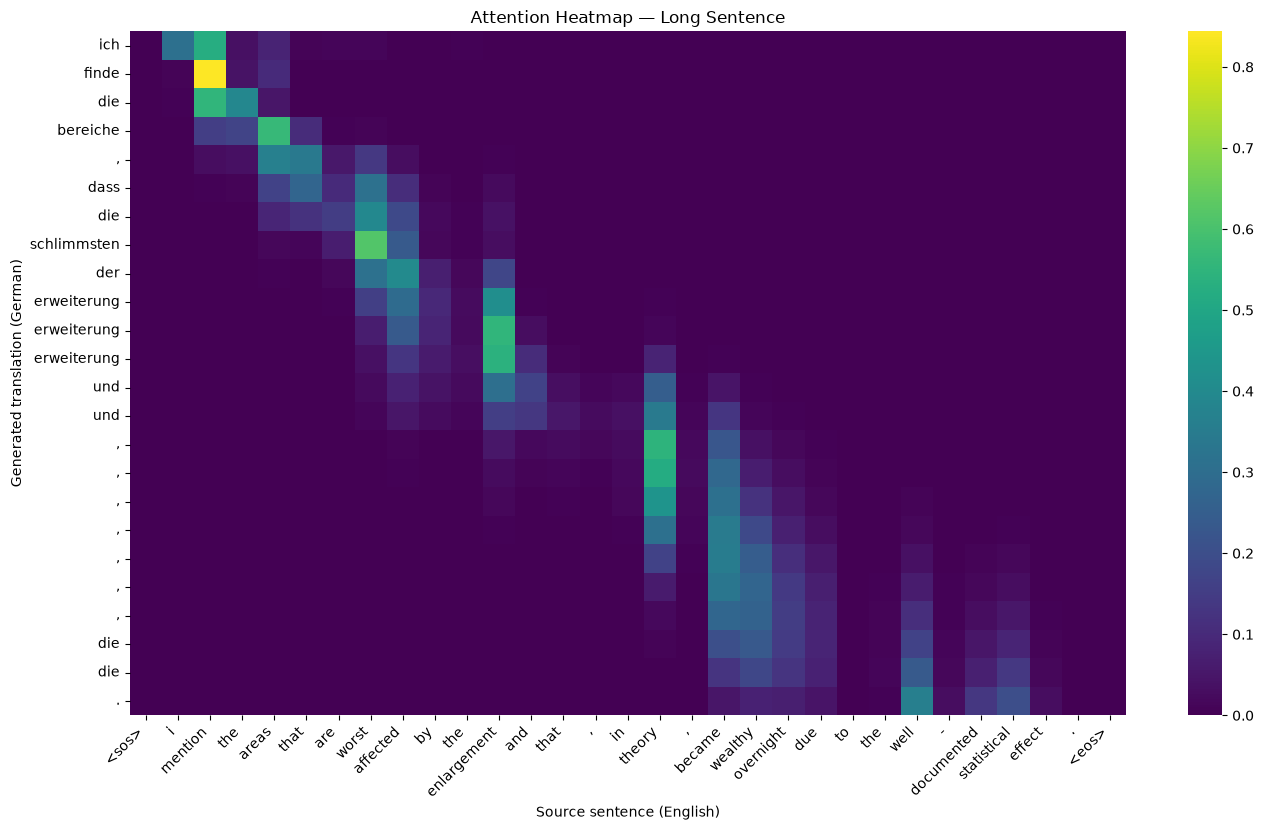

In [74]:
# Three attention heatmaps:
# 1. Short sentence
# 2. Medium sentence
# 3. Long sentence

examples = [
    (2, "Attention Heatmap — Short Sentence"),
    (4, "Attention Heatmap — Medium Sentence"),
    (0, "Attention Heatmap — Long Sentence")
]

for index, title in examples:

    example = val_data[index]["translation"]

    source = example["en"]
    reference = example["de"]

    translation, src_tokens, attention = translate_sentence(
        source,
        model,
        spacy_en,
        en_stoi,
        en_itos,
        de_stoi,
        de_itos,
        device
    )

    # Make sure attention rows match generated tokens
    attention = attention[:len(translation)]

    print("=" * 100)
    print(title)

    print("\nSOURCE:")
    print(source)

    print("\nREFERENCE:")
    print(reference)

    print("\nPREDICTION:")
    print(" ".join(translation))

    print("\nAttention shape:", attention.shape)

    plt.figure(
        figsize=(
            max(10, len(src_tokens) * 0.45),
            max(5, len(translation) * 0.35)
        )
    )

    sns.heatmap(
        attention,
        xticklabels=src_tokens,
        yticklabels=translation,
        cmap="viridis",
        cbar=True
    )

    plt.xlabel("Source sentence (English)")
    plt.ylabel("Generated translation (German)")
    plt.title(title)

    plt.xticks(
        rotation=45,
        ha="right"
    )

    plt.yticks(rotation=0)

    plt.tight_layout()
    plt.show()

Візуалізація ваг attention показує, що модель навчилася встановлювати зв'язок між словами вихідного англійського речення та словами німецького перекладу. На теплових картах світліші області відповідають більшим вагам attention, тобто показують, на які слова вихідної послідовності модель звертала найбільшу увагу під час генерації конкретного слова перекладу.
Коротке речення. Для речення “That can and will happen.” добре видно послідовне зміщення уваги від that до can, and, will та happen. Наприклад, при генерації перших слів найбільші ваги припадають на that і can. Це свідчить про те, що attention навчився базовому вирівнюванню між двома мовами. Водночас переклад dies können und und . . містить повторення та граматичні помилки, тому правильний фокус attention ще не гарантує правильного вибору слова Decoder-ом.
Речення середньої довжини. Тут структура attention виражена ще краще: на heatmap помітна діагональна тенденція, коли фокус поступово переміщується вздовж вихідного речення. Особливо добре видно зв'язки Mr → Herr, President → Präsident, а наприкінці речення модель переносить увагу на time, this, morning під час генерації morgen früh. Prediction уже передає частину змісту вихідного речення, хоча залишається граматично неточним.
Довге речення. Для довшої послідовності attention також поступово переміщується вздовж source sentence, однак його поведінка стає менш стабільною. Модель кілька разів генерує Erweiterung, und та розділові знаки. Це показує, що зі збільшенням довжини речення простій Seq2Seq GRU-моделі стає складніше підтримувати правильний стан Decoder-а та генерувати зв'язну цільову послідовність.
Отже, механізм attention працює та навчився знаходити релевантні частини вихідного речення. Найчіткіше вирівнювання спостерігається для коротких і середніх послідовностей. Для довших речень якість перекладу погіршується та виникають повторення, хоча сам attention продовжує зміщувати фокус уздовж вихідної послідовності. Це демонструє як переваги attention порівняно з використанням лише одного context vector, так і обмеження базової Seq2Seq GRU-архітектури.

### Висновок

У межах роботи було розроблено модель машинного перекладу з англійської на німецьку мову на основі набору даних Europarl. Для реалізації використано архітектуру Seq2Seq на основі GRU з механізмом Attention. Модель складається з двонаправленого Encoder, Decoder та механізму уваги, який дозволяє Decoder на кожному кроці генерації враховувати найбільш релевантні частини вихідного речення.
Перед навчанням було виконано підготовку даних: токенізацію текстів, аналіз довжини речень, фільтрацію послідовностей до 60 токенів, побудову окремих словників для англійської та німецької мов, перетворення токенів у числові індекси та формування батчів із padding. Після фільтрації було отримано 42 768 навчальних та 4 753 валідаційних приклади.
Для навчання використовувалися CrossEntropyLoss з ігноруванням <pad> токенів та оптимізатор Adam. Під час початкового навчання training loss зменшився з 5.913 до 4.127. Додатковий fine-tuning зі зменшеним learning rate та поступовим зменшенням teacher forcing дозволив отримати фінальний training loss близько 4.071, а найкращий validation loss покращити з 5.395 до 5.195.
Аналіз згенерованих перекладів показав, що модель навчилася правильно визначати значення окремих слів і коротких фраз та частково відтворювати структуру речень. Водночас у складних і довгих послідовностях виникають граматичні помилки, пропуски та повторення слів. Помітний розрив між training та validation loss також свідчить про певне перенавчання та обмежену здатність моделі до узагальнення.
Візуалізація Attention підтвердила, що механізм уваги працює: на heatmaps видно поступове переміщення фокусу вздовж вихідного речення та зв'язки між відповідними англійськими й німецькими словами. Найчіткіше вирівнювання спостерігається для коротких і середніх речень, тоді як для довших послідовностей attention стає менш стабільним, а якість генерації погіршується.
Таким чином, побудована Seq2Seq GRU + Attention модель успішно демонструє основний принцип нейронного машинного перекладу та роботу механізму уваги. Водночас отримані результати показують обмеження класичних рекурентних Seq2Seq-моделей при роботі з довгими та складними реченнями. Подальше покращення можливе завдяки збільшенню обсягу навчальних даних, оптимізації гіперпараметрів, регуляризації або використанню сучасніших архітектур на основі Transformer.